<a href="https://colab.research.google.com/github/hamzafarooq/multi-agent-course/blob/main/FDE-03-assignments/ReAct_vs_Router_1_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ReAct vs Router, Notebook 1: from scratch in Python**

Two ways to let an LLM use tools:

- **Router**: the model makes **one** decision: which **branch** should handle this question? That branch runs **once**, and the model writes the answer.
- **ReAct** (Reason + Act): the model works in a **loop**. It thinks, calls a tool, reads the result, and decides what to do next, until it has enough to answer.

```
               ROUTER                                      ReAct

              question                                    question
                 |                                           |
                 v                                           v
        LLM picks ONE branch                       LLM: Thought + Action  <------+
        /        |         \                                 |                   |
       v         v          v                                v                   |
 search_web  search_docs  calculator               tool runs: Observation -------+
       \         |         /                                 |     (repeat until done)
        v        v        v                                  v
       LLM writes the answer                            Final Answer

 Only the chosen branch runs, once.                Any tool, as many times as needed.
```

This notebook builds both from scratch in plain Python. It runs on an OpenAI model and uses SerpApi for web search.

**What you will do**

| Section | What happens |
|---|---|
| 1.1 to 1.2 | Build three tools: web search, a company-docs lookup and a calculator |
| 1.3 | Build a Router in about 10 lines |
| 1.4 | Build a ReAct loop in about 15 lines |
| 1.5 | Run both on the same question and see where the Router stops |
| 1.6 | **Exercise:** add your own tool |
| 1.7 | **Eval:** score the Router and the ReAct loop on the same 12 questions |

**About the numbers in the text.** The results quoted in this notebook (call counts, the exchange rate) come from one real run. Model answers and live search results change from run to run, so yours will differ a little.

# **Setup**

### Add your keys

Add your keys in Colab's **Secrets** panel (the key icon in the left sidebar) and switch on **Notebook access** for each one.

| Secret name | Needed for | Where to get it |
|---|---|---|
| `OPENAI_API_KEY` | The model | [platform.openai.com](https://platform.openai.com) |
| `SERP_API_KEY` | The web search tool | [serpapi.com](https://serpapi.com) |

Running locally instead of Colab? Set the same names as environment variables.

### Install the packages

One package: the `openai` client.

In [1]:
!pip install -q openai

### Load the keys

This cell reads the two keys and stops with a clear message if one is missing.

In [2]:
import os

def get_key(name):
    """Read a key from Colab Secrets, or from an environment variable when running locally."""
    try:
        from google.colab import userdata  # only exists on Colab
        return userdata.get(name)
    except Exception:  # not on Colab, or the secret is not set
        return os.environ.get(name)

# Load the two keys. A missing key comes back as None.
OPENAI_API_KEY = get_key("OPENAI_API_KEY")
SERP_API_KEY = get_key("SERP_API_KEY")

# Stop here with a clear message if a key is missing.
assert OPENAI_API_KEY, "Add OPENAI_API_KEY (see the table above)."
assert SERP_API_KEY, "Add SERP_API_KEY (see the table above)."
print("Keys loaded.")

Keys loaded.


### Connect to the model

This cell sets up four small things that the rest of the notebook uses:

- **`llm()`** sends a list of messages to the model and returns its reply as text.
- **`CALLS`** is a list that records every LLM call and tool call in order. We use it later to compare what the Router and the ReAct loop cost.
- **`TOKENS`** is a list that records how many tokens each LLM call used, prompt plus reply. Tokens are what you pay for.
- **`show()`** prints a title bar above an output, so you can always see which call produced which result.

In [26]:
from openai import OpenAI

client = OpenAI(api_key=OPENAI_API_KEY)
MODEL = "gpt-5.6-luna"

CALLS = []   # every LLM call and tool call, in order
TOKENS = []  # the tokens used by each LLM call

def llm(messages):
    """Send the messages to the model and return its reply as text."""
    CALLS.append("llm")  # count this call
    response = client.chat.completions.create(model=MODEL, messages=messages)
    TOKENS.append(response.usage.total_tokens)  # what this call cost: prompt plus reply
    return response.choices[0].message.content

def show(title, body=None):
    """Print a title bar, then the body, so every output says what produced it."""
    print(f"\n{'=' * 80}\n {title}\n{'=' * 80}")
    if body is not None:
        print(body)

show("This notebook uses this model", MODEL)


 This notebook uses this model
gpt-5.6-luna


# **Router and ReAct from scratch**

## **1.1 Tools**

A tool is a plain Python function: **a string goes in, a string comes out**.

The docstring matters. It is the description the model reads to decide **when** to use the tool, so write it for the model.



### Tool 1: `search_docs`

A tiny stand-in for RAG: four short documents from a made-up company, Acme. The model has never seen these, so it cannot answer from memory.

In [4]:
import re

# The whole knowledge base: four short documents, title -> text.
DOCS = {
    "Travel policy": "Employees may spend up to 180 US dollars per night on hotels and 60 US dollars per day on meals. Flights are booked in economy class.",
    "Remote work policy": "Employees may work remotely up to 3 days per week. Core hours are 10:00 to 15:00 in the employee's local time zone.",
    "Laptop policy": "Laptops are replaced every 4 years. The laptop budget is 2,000 US dollars per employee.",
    "Vacation policy": "Employees get 25 paid vacation days per year. Up to 5 unused days carry over to the next year.",
}

def search_docs(query: str) -> str:
    """Search the Acme company handbook (travel, remote work, laptop and vacation policies)."""

    # shortcut: keyword overlap, fine for 4 documents. Use embeddings (real RAG) for a real corpus.

    # 1. Keep the query's words that have 4 or more letters.
    words = set(re.findall(r"[a-z]{4,}", query.lower()))

    # 2. Score a document by how many of those words it contains.
    score = lambda title: sum(word in (title + " " + DOCS[title]).lower() for word in words)

    # 3. Take the best one. If nothing matched at all, say so.
    best = max(DOCS, key=score)
    return f"{best}: {DOCS[best]}" if score(best) else "No matching document."

### Tool 2: `search_web`

A live Google search through SerpApi. It returns Google's direct answer (if there is one) and the top three result snippets.

In [5]:
import requests

def search_web(query: str) -> str:
    """Search the live internet (Google) for current or external information."""

    # 1. Ask SerpApi to run a Google search.
    try:
        response = requests.get("https://serpapi.com/search.json", timeout=30,
                                params={"q": query, "api_key": SERP_API_KEY, "engine": "google", "num": 3})
        response.raise_for_status()  # a bad key or an empty quota counts as a failure
    except requests.exceptions.RequestException as error:
        # Return the error's name only: the full message can contain the API key.
        return f"Search error: {type(error).__name__}"
    data = response.json()

    # 2. Google's direct answer, when it shows one (an exchange rate, for example).
    box = data.get("answer_box", {})
    parts = [str(box[key]) for key in ("answer", "result", "snippet") if box.get(key)][:1]

    # 3. Then the title and snippet of the top 3 results.
    parts += [f"{r.get('title', '')}: {r['snippet']}" for r in data.get("organic_results", [])[:3] if r.get("snippet")]
    return "\n".join(parts) or "No results found."

### Tool 3: `calculator`

LLMs are unreliable at arithmetic, so we give them a calculator. It only accepts digits and `+ - * / ( ) %`, and refuses anything else.

In [6]:
def calculator(expression: str) -> str:
    """Evaluate an arithmetic expression, e.g. (180 - 60) / 60 * 100"""

    # 1. Safety first: only digits, spaces and arithmetic symbols may pass.
    if not re.fullmatch(r"[\d\s.+\-*/()%]+", expression):
        return "Error: only numbers and + - * / ( ) % are allowed."

    # 2. Work it out. eval gets no built-in functions, so arithmetic is all it can do.
    try:
        return str(eval(expression, {"__builtins__": {}}))
    except Exception as error:  # a division by zero, for example
        return f"Error: {error}"

### The toolbox

`TOOLS` maps each tool's name to its function. `tool_list()` turns it into text we can paste into a prompt. This is all the model ever sees of your tools: **names and docstrings**.

In [7]:
# The toolbox: tool name -> function. A new tool is one more entry here.
TOOLS = {fn.__name__: fn for fn in (search_web, search_docs, calculator)}

def tool_list() -> str:
    """The tool names and descriptions, as text for a prompt."""

    # One line per tool. The docstring is the description the model reads.
    return "\n".join(f"- {name}: {fn.__doc__}" for name, fn in TOOLS.items())

show("What the model will see of your tools", tool_list())


 What the model will see of your tools
- search_web: Search the live internet (Google) for current or external information.
- search_docs: Search the Acme company handbook (travel, remote work, laptop and vacation policies).
- calculator: Evaluate an arithmetic expression, e.g. (180 - 60) / 60 * 100


### Try each tool by hand

Call every tool yourself before giving it to a model. Each result is printed under the call that produced it.

The `assert` lines at the end are small tests: they stop the notebook if a tool misbehaves.

In [8]:
# Call each tool directly, with no model involved.
show('search_docs("hotel limit")', search_docs("hotel limit"))
show('calculator("(180 - 60) / 60 * 100")', calculator("(180 - 60) / 60 * 100"))
show('search_web("USD to EUR exchange rate")', search_web("USD to EUR exchange rate"))

# Small tests: a line here fails loudly if a tool misbehaves.
assert search_docs("how many vacation days").startswith("Vacation policy")
assert search_docs("xyzzy") == "No matching document."
assert calculator("2 * (3 + 4)") == "14"
assert calculator("__import__('os')").startswith("Error")  # code is refused, not run
show("Tool tests", "All 4 passed.")


 search_docs("hotel limit")
Travel policy: Employees may spend up to 180 US dollars per night on hotels and 60 US dollars per day on meals. Flights are booked in economy class.

 calculator("(180 - 60) / 60 * 100")
200.0

 search_web("USD to EUR exchange rate")
0.91 Euro
Currency converter from USD to EUR: Calculator to convert money from U.S. Dollar (USD) to Euro (EUR) using up to date exchange rates. From USD. To EUR. Graph for USD per EUR.
USD to EUR: Convert US dollar to euro: 1 USD = 0.9112 EUR (ECB reference rate, 2026-11-26). Convert US dollars to euros, with a one-year chart and conversion table.
US Dollar to European Euro: Users can check the exchange rate today and convert USD to EUR and EUR to USD in a few seconds.

 Tool tests
All 4 passed.


## **1.2 Letting the model call a tool**

A model can only write text. So we agree on a format: when it wants a tool, it writes two lines.

```
Action: calculator
Action Input: 2 + 2
```

`run_tool()` finds those two lines in the model's reply and runs the tool.

In [9]:
# The two lines the model must write: 'Action: <tool>' then 'Action Input: <input>'.
ACTION = re.compile(r"Action:\s*(\w+)\s*\nAction Input:\s*(.*)")  # the input is one line

def run_tool(reply: str) -> str:
    """Find 'Action' and 'Action Input' in the model's reply, run that tool, return its result."""

    # 1. Look for the two lines. If the model ignored the format, tell it how to reply.
    action = ACTION.search(reply)
    if not action:
        return "Error: reply with 'Action: <tool name>' then 'Action Input: <input>'."

    # 2. Check the tool exists. Models sometimes invent one.
    name, tool_input = action.group(1), action.group(2).strip()
    if name not in TOOLS:
        return f"Error: unknown tool '{name}'. Choose from: {', '.join(TOOLS)}"

    # 3. Run it. The name picks the function: this is the branching.
    CALLS.append(name)  # count this tool call
    return TOOLS[name](tool_input)

### Test it without a model

We can write the "model's reply" by hand. The first reply asks for a real tool. The second asks for a tool that does not exist, so `run_tool()` answers with an error the model can read.

In [10]:
# No model needed: the two replies below are written by hand.
for reply in ("Action: calculator\nAction Input: 2 + 2", "Action: fly_to_moon\nAction Input: now"):
    show("If the model replies", reply)
    print(f"\nrun_tool() returns: {run_tool(reply)}")


 If the model replies
Action: calculator
Action Input: 2 + 2

run_tool() returns: 4

 If the model replies
Action: fly_to_moon
Action Input: now

run_tool() returns: Error: unknown tool 'fly_to_moon'. Choose from: search_web, search_docs, calculator


### A helper to run an agent

`run()` is a small helper for this notebook. It runs one agent on one question, then prints the answer, the calls it made in order, and how many of each.

In [11]:
def run(agent, question):
    """Run one agent on one question, then show its answer and every call it made."""
    CALLS.clear()  # start counting from zero
    show(f"{agent.__name__.upper()}  |  {question}")
    answer = agent(question)

    # The summary: the answer, the calls in order, and how many of each.
    llm_calls = CALLS.count("llm")
    print(f"\n{'-' * 80}\nANSWER: {answer}")
    print(f"CALLS:  {' > '.join(CALLS)}   (LLM calls: {llm_calls}, tool calls: {len(CALLS) - llm_calls})")

## **1.3 The Router**

A router sends each question down **one branch**. Here there are three branches, one per tool: web, docs and calculator. (In a real product a branch is often a whole pipeline, such as "answer from the docs" or "hand over to a human".)

Three steps, always the same:

1. **LLM call 1:** pick ONE branch (a tool) and its input.
2. Run that tool, once.
3. **LLM call 2:** write the answer from that one result.

There is no way back and no second branch. If the tool result is not enough, the Router can only say so.

### The two prompts

One prompt for each LLM call.

In [12]:
# LLM call 1 uses this prompt: choose one tool.
ROUTER_PROMPT = """Pick the ONE tool that is best for answering the question.

Tools:
{tools}

Reply in exactly this format and nothing else:
Action: <one tool name from the list>
Action Input: <the input for the tool>

Question: {question}"""

# LLM call 2 uses this prompt: answer from the tool result only.
ANSWER_PROMPT = """Answer the question using ONLY the tool result below.
If the tool result is not enough to answer, say what is missing.

Question: {question}

Tool result: {result}"""

### The router function

The three steps, in code.

In [13]:
def router(question: str) -> str:
    """One decision, one tool call, one answer. Always 2 LLM calls."""

    # 1. Ask the model which tool to use (LLM call 1).
    choice = llm([{"role": "user", "content": ROUTER_PROMPT.format(tools=tool_list(), question=question)}])
    print(f"\n[1] The model picks ONE tool\n{choice}")

    # 2. Run that one tool, once.
    result = run_tool(choice)
    print(f"\n[2] The tool runs once\nObservation: {result}")

    # 3. Ask the model to write the answer from the result (LLM call 2).
    print("\n[3] The model writes the answer")
    return llm([{"role": "user", "content": ANSWER_PROMPT.format(question=question, result=result)}])

### Run it on an easy question

One tool is enough for this one.

In [14]:
EASY = "How many vacation days do I get per year?"

run(router, EASY)


 ROUTER  |  How many vacation days do I get per year?

[1] The model picks ONE tool
Action: search_docs
Action Input: vacation days per year policy

[2] The tool runs once
Observation: Vacation policy: Employees get 25 paid vacation days per year. Up to 5 unused days carry over to the next year.

[3] The model writes the answer

--------------------------------------------------------------------------------
ANSWER: You get 25 paid vacation days per year.
CALLS:  llm > search_docs > llm   (LLM calls: 2, tool calls: 1)


## **1.4 The ReAct loop**

Same tools, same `Action` format. Two things change:

- The prompt offers a second option: `Final Answer`.
- We call the model **in a loop**. Each tool result goes back to the model as an `Observation`, and the model decides what to do next. The loop ends when the model writes `Final Answer`, or when it hits `max_steps` (a safety cap, so a confused model cannot loop forever).

### The prompt

It lists the tools, the two reply formats and the rules.

In [15]:
# The system prompt: the tools, the reply format and the rules.
REACT_PROMPT = """Answer the question by thinking step by step and using tools.

Tools:
{tools}

On every turn, reply in EXACTLY one of these two formats and nothing else:

Thought: <what you need to do next>
Action: <one tool name from the list>
Action Input: <the input for the tool>

or, once you have everything you need:

Thought: <your final reasoning>
Final Answer: <the answer to the question>

Rules:
- ONE action per turn, then stop. You will be given the Observation.
- Only use facts that appear in an Observation. Never answer from memory.
- Use the calculator for any arithmetic.
- Keep the Final Answer to one or two sentences."""

### The loop

One guard is worth noticing. Models sometimes "run ahead": they write an action and then invent the tool's result themselves. So we keep only the first action from each reply and throw the rest away.

In [16]:
def react(question: str, max_steps: int = 8) -> str:
    """Think, act, observe, repeat. Stops at a Final Answer or after max_steps turns."""

    # The conversation so far. It grows by two messages on every turn.
    messages = [{"role": "system", "content": REACT_PROMPT.format(tools=tool_list())},
                {"role": "user", "content": f"Question: {question}"}]

    # The loop, with a cap so it cannot run forever.
    for step in range(1, max_steps + 1):

        # 1. Ask the model. Models sometimes run ahead and invent the tool result, so keep the first action only.
        reply = llm(messages).split("Observation:")[0].strip()
        action = ACTION.search(reply)
        if action:
            reply = reply[:action.end()]

        # 2. Remember what the model said.
        messages.append({"role": "assistant", "content": reply})
        print(f"\n--- Step {step} {'-' * 69}\n{reply}")

        # 3. No action and a Final Answer: we are done.
        if not action and "Final Answer:" in reply:
            return reply.split("Final Answer:")[1].strip()

        # 4. Otherwise run the tool it asked for and hand the result back as the Observation.
        observation = run_tool(reply)
        print(f"Observation: {observation}")
        messages.append({"role": "user", "content": f"Observation: {observation}"})

    return "Stopped: reached max steps without a final answer."

### Run it on the same easy question

In [17]:
run(react, EASY)


 REACT  |  How many vacation days do I get per year?

--- Step 1 ---------------------------------------------------------------------
Thought: I need to look up the vacation policy to determine the annual vacation allowance.
Action: search_docs
Action Input: vacation days per year policy allowance
Observation: Vacation policy: Employees get 25 paid vacation days per year. Up to 5 unused days carry over to the next year.

--- Step 2 ---------------------------------------------------------------------
Thought: The policy states the annual vacation allowance is 25 paid days.
Final Answer: You get 25 paid vacation days per year.

--------------------------------------------------------------------------------
ANSWER: You get 25 paid vacation days per year.
CALLS:  llm > search_docs > llm   (LLM calls: 2, tool calls: 1)


On an easy question the two behave the same: one tool call, the same answer (25 days) and the same number of LLM calls. If every question looked like this, the Router would be the better choice, because it is simpler and its cost never changes.

## **1.5 Where they differ**

Now a question that needs **three** things:

1. a figure from the company docs (the hotel limit, in US dollars),
2. a live fact from the web (today's exchange rate),
3. arithmetic on the two.

No single tool call can cover that.

### The Router on the hard question

In [18]:
HARD = "What is our hotel limit per night, converted to euros at today's exchange rate?"

run(router, HARD)


 ROUTER  |  What is our hotel limit per night, converted to euros at today's exchange rate?

[1] The model picks ONE tool
Action: search_docs
Action Input: Find the company hotel limit per night, including the currency.

[2] The tool runs once
Observation: Travel policy: Employees may spend up to 180 US dollars per night on hotels and 60 US dollars per day on meals. Flights are booked in economy class.

[3] The model writes the answer

--------------------------------------------------------------------------------
ANSWER: The hotel limit is **$180 per night**. The exchange rate for today is not provided, so it cannot be converted to euros.
CALLS:  llm > search_docs > llm   (LLM calls: 2, tool calls: 1)


**Behind the scenes.** The same kind of run as an animation: every message that moved between your Python, the model and the tool, with its exact text.

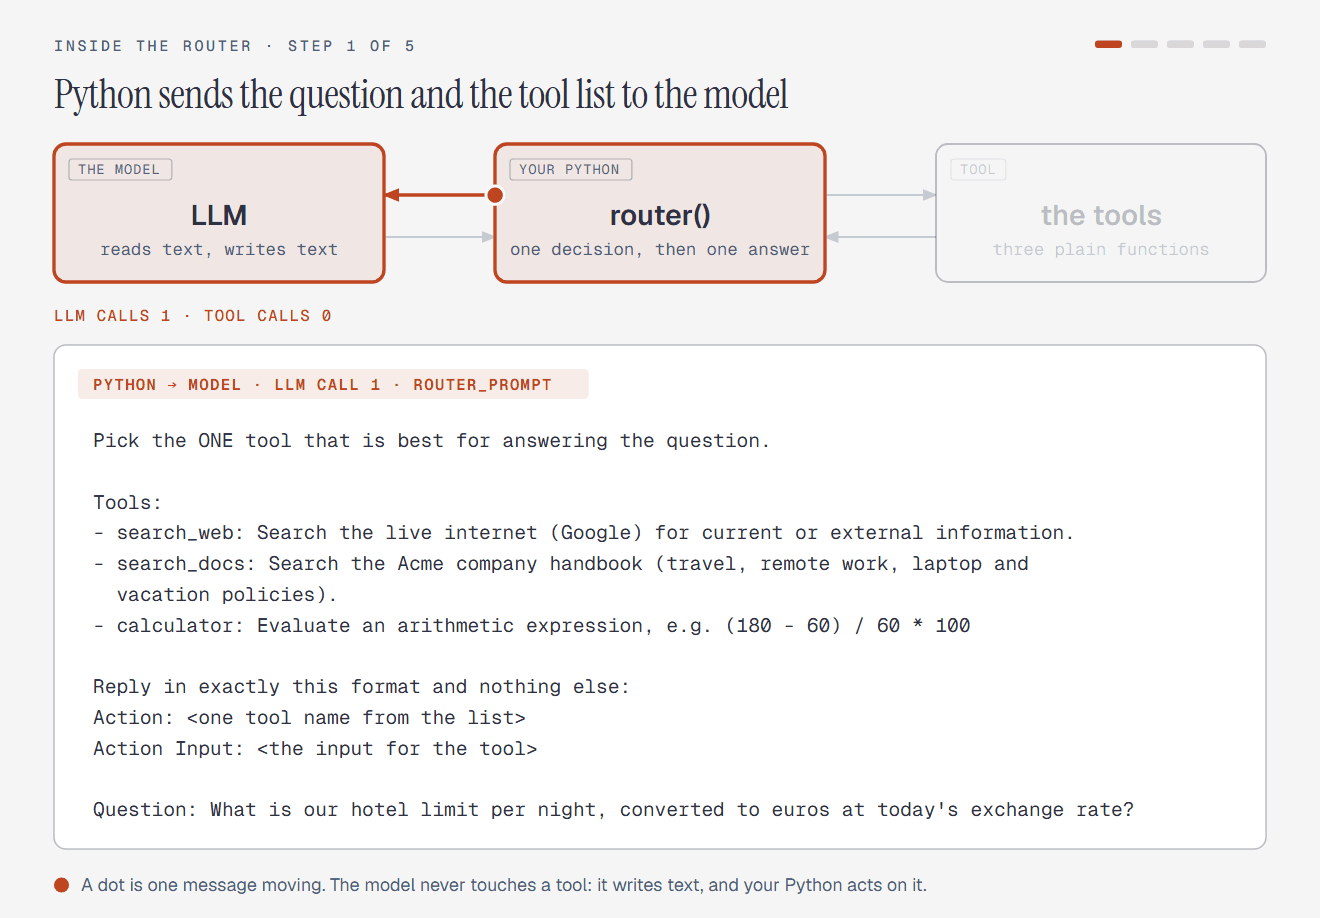

*Recorded from an earlier run. Values and wording change from run to run, so this will not match the output above exactly.*

### The ReAct loop on the same question

In [19]:
run(react, HARD)


 REACT  |  What is our hotel limit per night, converted to euros at today's exchange rate?

--- Step 1 ---------------------------------------------------------------------
Thought: I need to find the company’s hotel limit in the handbook.
Action: search_docs
Action Input: hotel limit per night travel policy
Observation: Travel policy: Employees may spend up to 180 US dollars per night on hotels and 60 US dollars per day on meals. Flights are booked in economy class.

--- Step 2 ---------------------------------------------------------------------
Thought: I need today’s USD-to-EUR exchange rate to convert the $180 hotel limit.
Action: search_web
Action Input: today's USD to EUR exchange rate 180 USD in EUR
Observation: US dollar to Euros Exchange Rate History: The exchange rate for US dollar to Euros is currently 0.912575 today, reflecting a 0.123% change since yesterday.
1 USD to EUR - US Dollars to Euros Exchange Rate: 1.00 USD = 0.91408490. As of 16:00 UTC, the mid-market USD to E

**Behind the scenes.** The same kind of run as an animation. Watch the conversation grow: Python sends all of it back to the model on every round.

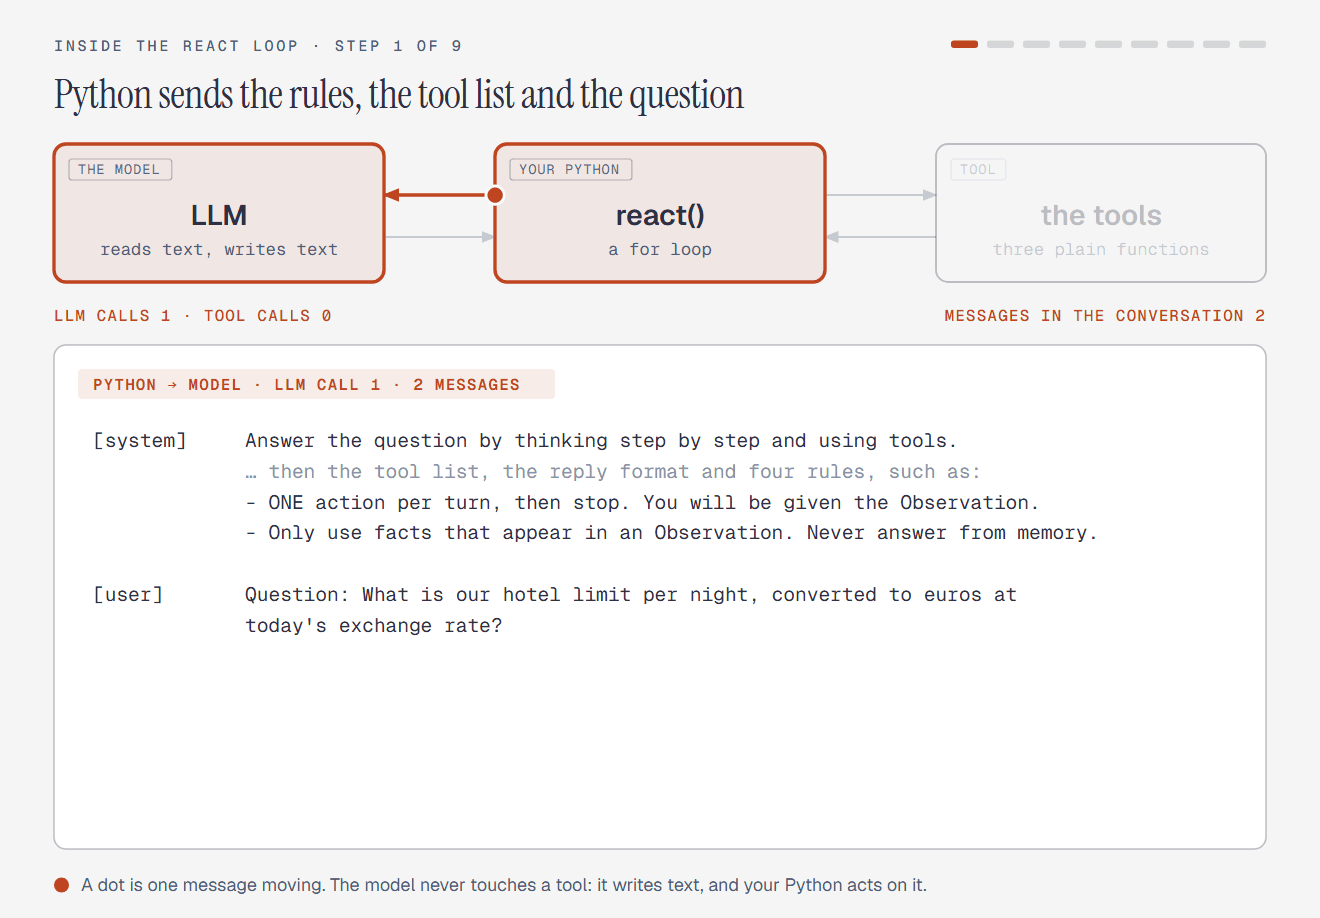

*Recorded from an earlier run. Values and wording change from run to run, so this will not match the output above exactly.*

### What happened

Same question, same tools, same model. The animation shows a Router run and a ReAct run on this question, with both sides moving at the same time.

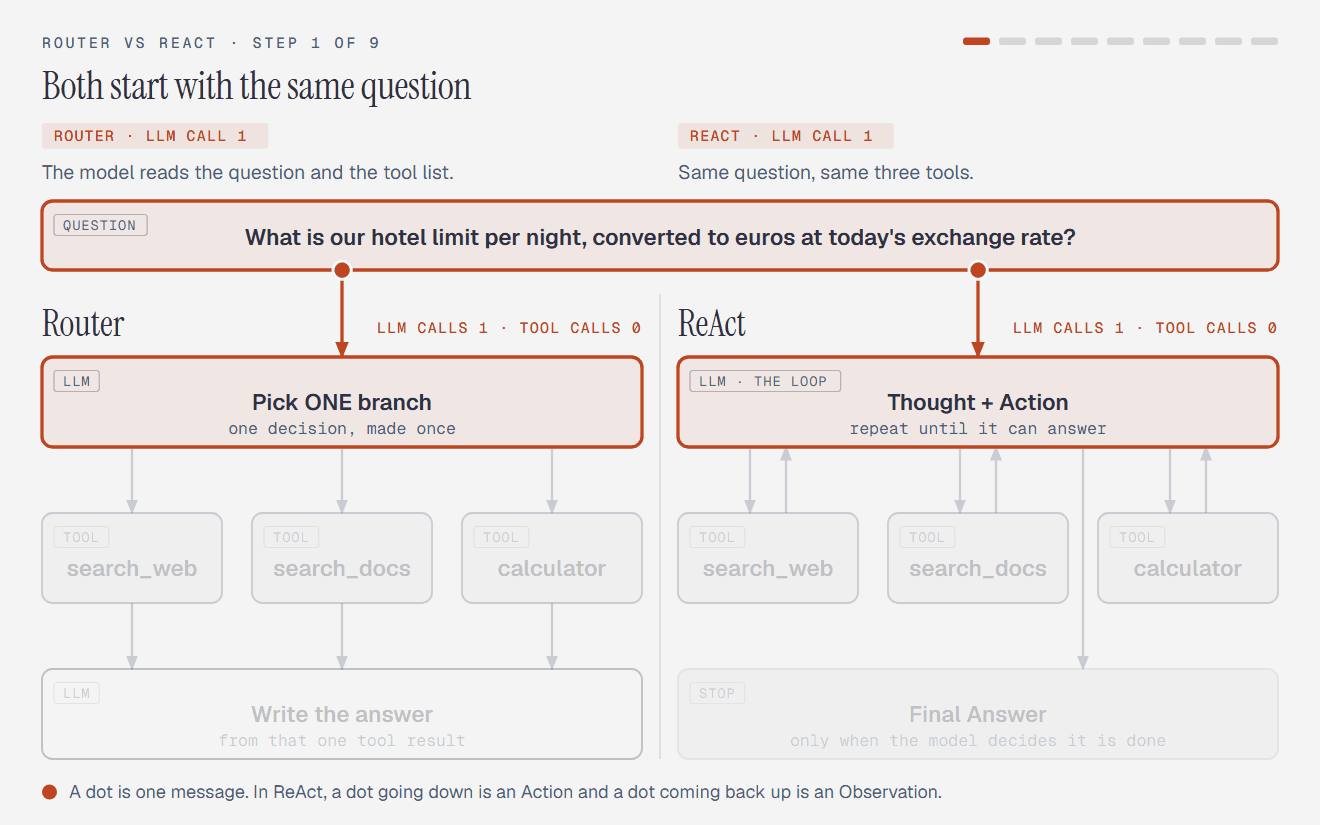

*Recorded from an earlier run. Values and wording change from run to run, so this will not match the output above exactly.*

| | Router | ReAct |
|---|---|---|
| Tools used | `search_docs` only | `search_docs`, then `search_web`, then `calculator` |
| LLM calls | 2 | 4 |
| Answer | The limit is 180 US dollars, but the exchange rate is missing, so it cannot convert | About 164 euros (180 x 0.912575, the rate found on the day of this run) |

- **The Router picked a sensible tool** and found the 180 dollar limit. Then it was stuck: it has no second call to fetch the exchange rate, so the best it can do is report what is missing.
- **That honest "missing" answer is not luck.** It comes from the line in `ANSWER_PROMPT` that says to use only the tool result. Delete that line and run it again: the model is then free to fill the gap from memory, which is worse, because the answer looks complete.
- **ReAct used each result to choose the next step.** The docs gave dollars, so it went to the web for a rate, then to the calculator for the arithmetic.
- **The price:** twice the LLM calls here (4 instead of 2), and you cannot know the number in advance.

## **1.6 Exercise: add your own tool**

Adding a tool takes two things, and **no change to the Router or the loop**:

1. Write a function: a string goes in, a string comes out. Give it a docstring that tells the model **when** to use it.
2. Register it: `TOOLS["your_tool_name"] = your_tool_name`

The prompts are rebuilt from `TOOLS` on every call, so the model sees your tool straight away.

Ideas: today's date, a unit converter (km to miles), a word counter, a dice roll, a lookup in your own small dictionary of facts.

Fill in the cell below.

In [20]:
# 1. Write your tool. Keep the type hints: frameworks such as ADK read them.
#
# def my_tool(text: str) -> str:
#     """Say what the tool does and when the model should use it."""
#     return "..."

# 2. Register it.
#
# TOOLS["my_tool"] = my_tool

<details>
<summary><b>Stuck? Click for a worked example</b> (a tool that returns today's date)</summary>

```python
from datetime import date

def get_today(text: str) -> str:
    """Get today's date. The input is ignored."""
    return date.today().isoformat()

TOOLS["get_today"] = get_today
```

Then in the check cell below set `MY_TOOL = "get_today"` and `MY_QUESTION = "What is today's date?"`.

</details>

### Check your tool

Set the two names, then run the cell. It checks three things: the tool has a docstring, it returns a string, and the ReAct agent actually **uses** it on your question.

In [21]:
# Fill in these two.
MY_TOOL = "my_tool"                    # the name you registered
MY_QUESTION = "Ask something here."    # a question that needs your tool

# Skip politely until the tool exists, so Run All still works.
if MY_TOOL not in TOOLS:
    show("Exercise check", f"'{MY_TOOL}' is not in TOOLS yet. Do the exercise above, then run this cell again.")
else:
    # Three checks: it has a description, it returns text, and the agent really used it.
    assert TOOLS[MY_TOOL].__doc__, "Give your tool a docstring: it is the description the model reads."
    assert isinstance(TOOLS[MY_TOOL]("test"), str), "A tool must return a string."
    run(react, MY_QUESTION)
    assert MY_TOOL in CALLS, "The agent answered without your tool. Make the docstring say clearly when to use it."
    show("Exercise check", f"Passed: the agent used '{MY_TOOL}'.")


 Exercise check
'my_tool' is not in TOOLS yet. Do the exercise above, then run this cell again.


## **1.7 Eval: Router vs ReAct on the same 12 questions**

Sections 1.3 to 1.5 compared the two agents on two questions, and you judged them by reading the output. That is a demo. An **eval** is a set of questions with known answers, scored the same way for every agent, so you can compare them, on accuracy and on cost, and say which agent does better on which **kind** of question.

This one has 12 questions in 4 kinds, three of each, from "one lookup" to "two documents, then arithmetic". Every answer is a number, so a few lines of code can check it.

**Before you run it:** which kinds do you expect the Router to get wrong?

### The questions

In [22]:
# Each row: the kind of question, the question, and the number a correct answer must contain.
EVAL = [
    ("One lookup",                 "How many paid vacation days do I get per year?", "25"),
    ("One lookup",                 "What is the laptop budget per employee?", "2000"),
    ("One lookup",                 "What is the daily meal limit when I travel?", "60"),
    ("One calculation",            "What is 18 percent of 2,450?", "441"),
    ("One calculation",            "What is 1,250 times 12?", "15000"),
    ("One calculation",            "What is 3,600 divided by 48?", "75"),
    ("One document + arithmetic",  "What is the most I can spend on hotels on a 4-night trip?", "720"),
    ("One document + arithmetic",  "What is the most I can spend on meals on a 5-day trip?", "300"),
    ("One document + arithmetic",  "Spread over the years a laptop is kept, what is the laptop budget per year?", "500"),
    ("Two documents + arithmetic", "How many hotel nights at the nightly limit does the laptop budget pay for?", "11"),
    ("Two documents + arithmetic", "What do hotels cost for all my paid vacation days, at the nightly limit?", "4500"),
    ("Two documents + arithmetic", "How many days of meals at the daily limit does the laptop budget pay for?", "33"),
]

### The scoring

- **`correct()`** checks one answer: does it contain the expected number?
- **`score()`** runs one agent on one question without printing its steps. It returns four things: whether the answer was correct, the number of LLM calls, the tokens used and the seconds it took.

In [27]:
import contextlib
import io
import time

def correct(answer, expected):
    """True when the expected number appears in the answer. Commas are ignored, so 15,000 matches 15000."""

    # shortcut: a number match, fine when every answer is one number. Use a model as the judge for free-text answers.
    return re.search(rf"(?<![\d.]){expected}(?!\d)", str(answer).replace(",", "")) is not None

def score(agent, question, expected):
    """Run one agent on one question, quietly. Return what it got right and what it cost."""
    CALLS.clear()   # start counting from zero
    TOKENS.clear()
    start = time.perf_counter()

    # Hide the step-by-step printing: 24 runs of it would bury the result.
    with contextlib.redirect_stdout(io.StringIO()):
        answer = agent(question)

    return {"ok": correct(answer, expected), "calls": CALLS.count("llm"),
            "tokens": sum(TOKENS), "seconds": time.perf_counter() - start}

# Small tests for the checker, with no model involved.
assert correct("That is 15,000 dollars.", "15000")
assert correct("About 11.11 nights.", "11")
assert not correct("The total is 1,441.", "441")  # 441 inside a longer number does not count
show("Checker tests", "All passed.")


 Checker tests
All passed.


### Run the eval

Both agents answer every question. That is roughly 60 LLM calls, so this cell takes longer than the earlier ones. None of the questions needs the web.

In [28]:
RESULTS = []  # one row per question
mark = lambda r: f"{'PASS' if r['ok'] else 'FAIL'}  {r['calls']} LLM calls  {r['tokens']:>6} tokens  {r['seconds']:5.1f}s"

show(f"Eval: {len(EVAL)} questions, both agents")
for number, (kind, question, expected) in enumerate(EVAL, 1):

    # Same question, same check, both agents.
    row = {"kind": kind, "router": score(router, question, expected), "react": score(react, question, expected)}
    RESULTS.append(row)

    print(f"\nQ{number} | {kind}\n    {question}")
    print(f"    Router  {mark(row['router'])}\n    ReAct   {mark(row['react'])}")


 Eval: 12 questions, both agents

Q1 | One lookup
    How many paid vacation days do I get per year?
    Router  pass  2 LLM calls     232 tokens    2.3s
    ReAct   pass  2 LLM calls     595 tokens    2.4s

Q2 | One lookup
    What is the laptop budget per employee?
    Router  pass  2 LLM calls     225 tokens    2.1s
    ReAct   pass  2 LLM calls     580 tokens    2.3s

Q3 | One lookup
    What is the daily meal limit when I travel?
    Router  pass  2 LLM calls     234 tokens    2.1s
    ReAct   pass  2 LLM calls     607 tokens    2.3s

Q4 | One calculation
    What is 18 percent of 2,450?
    Router  pass  2 LLM calls     199 tokens    1.6s
    ReAct   pass  1 LLM calls     262 tokens    1.1s

Q5 | One calculation
    What is 1,250 times 12?
    Router  pass  2 LLM calls     193 tokens    1.7s
    ReAct   pass  1 LLM calls     259 tokens    1.2s

Q6 | One calculation
    What is 3,600 divided by 48?
    Router  FAIL  2 LLM calls     270 tokens    2.8s
    ReAct   pass  2 LLM calls

### The score by kind of question

For each kind of question the code gives a verdict:

- The agent with **more correct answers** wins.
- If both score the same, the one that used **fewer tokens** is the better choice.
- If their tokens are within 10 percent of each other, there is **no clear winner**.

In [29]:
def average(rows, agent, field):
    """The average of one measurement (calls, tokens or seconds) for one agent."""
    return sum(row[agent][field] for row in rows) / len(rows)

def summary(rows, agent):
    """Like '3/3   2.0 calls     640 tokens    1.8s': correct answers, then the averages per question."""
    passed = sum(row[agent]["ok"] for row in rows)
    return (f"{f'{passed}/{len(rows)}':<5}  {average(rows, agent, 'calls'):4.1f} calls  "
            f"{average(rows, agent, 'tokens'):7.0f} tokens  {average(rows, agent, 'seconds'):5.1f}s")

def verdict(rows):
    """Which agent suits this kind of question: accuracy first, then cost."""

    # 1. More correct answers wins.
    router, react = (sum(row[agent]["ok"] for row in rows) for agent in ("router", "react"))
    if router != react:
        return f"{'ReAct' if react > router else 'Router'} wins: more correct answers"
    if router == 0:
        return "Neither: both got every question wrong"

    # 2. Same accuracy: the one that used fewer tokens, unless they are within 10 percent.
    r, a = average(rows, "router", "tokens"), average(rows, "react", "tokens")
    if abs(r - a) <= 0.1 * max(r, a):
        return "No clear winner: same accuracy, similar cost"
    return f"Same accuracy, {'Router' if r < a else 'ReAct'} is cheaper ({min(r, a) / max(r, a):.0%} of the tokens)"

show("Router vs ReAct by kind of question (averages per question)")

# One block per kind, in the order they appear in EVAL.
for kind in dict.fromkeys(row["kind"] for row in RESULTS):
    rows = [row for row in RESULTS if row["kind"] == kind]
    print(f"\n{kind}")
    print(f"    Router   {summary(rows, 'router')}")
    print(f"    ReAct    {summary(rows, 'react')}")
    print(f"    Verdict  {verdict(rows)}")

print(f"\n{'-' * 80}\nAll questions")
print(f"    Router   {summary(RESULTS, 'router')}")
print(f"    ReAct    {summary(RESULTS, 'react')}")


 Router vs ReAct by kind of question (averages per question)

One lookup
    Router   3/3     2.0 calls      230 tokens    2.2s
    ReAct    3/3     2.0 calls      594 tokens    2.3s
    Verdict  Same accuracy, Router is cheaper (39% of the tokens)

One calculation
    Router   2/3     2.0 calls      221 tokens    2.0s
    ReAct    3/3     1.3 calls      361 tokens    1.5s
    Verdict  ReAct wins: more correct answers

One document + arithmetic
    Router   3/3     2.0 calls      283 tokens    2.4s
    ReAct    3/3     3.0 calls     1061 tokens    4.2s
    Verdict  Same accuracy, Router is cheaper (27% of the tokens)

Two documents + arithmetic
    Router   0/3     2.0 calls      309 tokens    2.7s
    ReAct    3/3     4.0 calls     1571 tokens    5.5s
    Verdict  ReAct wins: more correct answers

--------------------------------------------------------------------------------
All questions
    Router   8/12    2.0 calls      261 tokens    2.3s
    ReAct    12/12   2.6 calls      897

### How to read the result

- **Accuracy first, cost second.** A cheaper agent that gets the answer wrong has not saved anything.
- **Where both agents pass, compare the tokens.** The two can make the same number of LLM calls and still differ in cost: the ReAct prompt is longer, and the loop sends the whole conversation again on every call.
- **Trust tokens more than seconds.** Seconds depend on the network and on how busy the model is, so a small difference in time means little.
- **Where only one agent passes, that kind of question needs something the other one lacks.** To see what, run the failed question with its steps printed, for example `run(router, EVAL[9][1])`.
- **The check is simple and strict.** A correct answer that never states the number counts as a fail, so read a surprising fail before you trust it.
- **Twelve questions is a small set, and models vary from run to run.** Run the eval twice. A result that flips between runs is not a result yet.

# **Key Takeaways**

| | Router | ReAct |
|---|---|---|
| How it works | One decision, one tool call | A loop: act, observe, decide again |
| LLM calls | Always 2 | As many as the question needs (2 on the easy question, 4 on the hard one in this run) |
| Cost and speed | Fixed and predictable | Varies with the question. Cap it with `max_steps` |
| Questions that need more than one tool call | Cannot answer them. At best it says what is missing | Can answer them |
| What can go wrong | It picks the wrong tool, and there is no second try | It loops, runs ahead or wanders, so it needs guards |
| Good fit | Many questions of a few clearly separate kinds | Open questions, where the next step depends on the last result |

**Rule of thumb:** start with a Router. Move to ReAct when you find questions it cannot answer in one step.

**And a tool is just a function with a good description.** The exercise in 1.6 needed nothing else: no change to the Router and no change to the loop.

**Where to go next**

- Try a question of your own that needs two tools, and predict what the Router will say before you run it.
- Open Notebook 2 (`ReAct_vs_Router_2_ADK.ipynb`): the same Router and ReAct agent built with Google's Agent Development Kit (ADK), where the loop and the parsing are done for you.